In [1]:
import numpy as np

from mpi4py import MPI
from petsc4py import PETSc

import dolfinx
import dolfinx.plot
import ufl
import basix.ufl

from fenicsx_ii import assemble_scalar, Circle, Average, assemble_matrix, LinearProblem, create_matrix, create_vector, assemble_vector

from mesh import GenMesh3D, GenMesh3DPerp
from GraphProblem import GraphProblem

In [5]:
N = 4

comm = MPI.COMM_WORLD
_, _, graph_nodes, graph_cells, cells_edges, lm_index, boundary_indices = GenMesh3DPerp(2*N)

ufl_int = ufl.Mesh(basix.ufl.element("Lagrange", "interval", 1, shape=(3,)))

graph_mesh = dolfinx.mesh.create_mesh(
    comm,
    e=ufl_int,
    cells=graph_cells,
    x=graph_nodes,
)

lm_mesh, lm_map = dolfinx.mesh.create_submesh(
    graph_mesh,
    graph_mesh.topology.dim - 1,
    lm_index
)[:2]


In [6]:
edge_meshes = []
edge_entity_maps = []
edge_vertex_maps = []
edge_facet_markers = []

marker_indices = np.insert(boundary_indices, 1, lm_index).astype(np.int32)
marker_values = np.array([2, 1, 2, 2], dtype=np.int32)

boundary_marker = 2
bifurc_marker = 1

global_facet_markers = dolfinx.mesh.meshtags(
    graph_mesh,
    0,
    marker_indices,
    marker_values,
)

parent_vertex_map = graph_mesh.topology.index_map(0)
num_vertices_parent = parent_vertex_map.size_local + parent_vertex_map.num_ghosts
parent_vertex_marker = np.full(num_vertices_parent, -1, dtype=np.int32)
parent_vertex_marker[global_facet_markers.indices] = global_facet_markers.values

num_cells_in_edge = len(cells_edges[0])
cells_array = np.arange(num_cells_in_edge, dtype=np.int32)
cell_indices = []
cell_indices.append(cells_array)
cell_indices.append(2*cells_array + num_cells_in_edge)
cell_indices.append(2*cells_array + 1 + num_cells_in_edge)

for i, edge_group in enumerate(cells_edges):

    edge_mesh, edge_map, vertex_map = dolfinx.mesh.create_submesh(
        graph_mesh,
        graph_mesh.topology.dim,
        cell_indices[i],
    )[:3]

    edge_meshes.append(edge_mesh)
    edge_entity_maps.append(edge_map)
    edge_vertex_maps.append(vertex_map)

    num_submesh_vertices = (
        edge_mesh.topology.index_map(0).size_local +
        edge_mesh.topology.index_map(0).num_ghosts
    )
    parent_vertices = vertex_map.sub_topology_to_topology(
        np.arange(num_submesh_vertices, dtype=np.int32), inverse=False
    )
    print(parent_vertices)
    sub_topology_values = parent_vertex_marker[parent_vertices]
    marked_vertices = np.flatnonzero(sub_topology_values >= 0)
    marked_values = sub_topology_values[marked_vertices].copy()

    edge_facet_markers.append(
        dolfinx.mesh.meshtags(edge_mesh, 0, marked_vertices.astype(np.int32), marked_values.astype(np.int32))
    )

[0 1 2 3 4]
[ 4  5  7  9 11]
[ 4  6  8 10 12]


/tmp/ipykernel_20062/497245233.py:17: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  plotter.show()


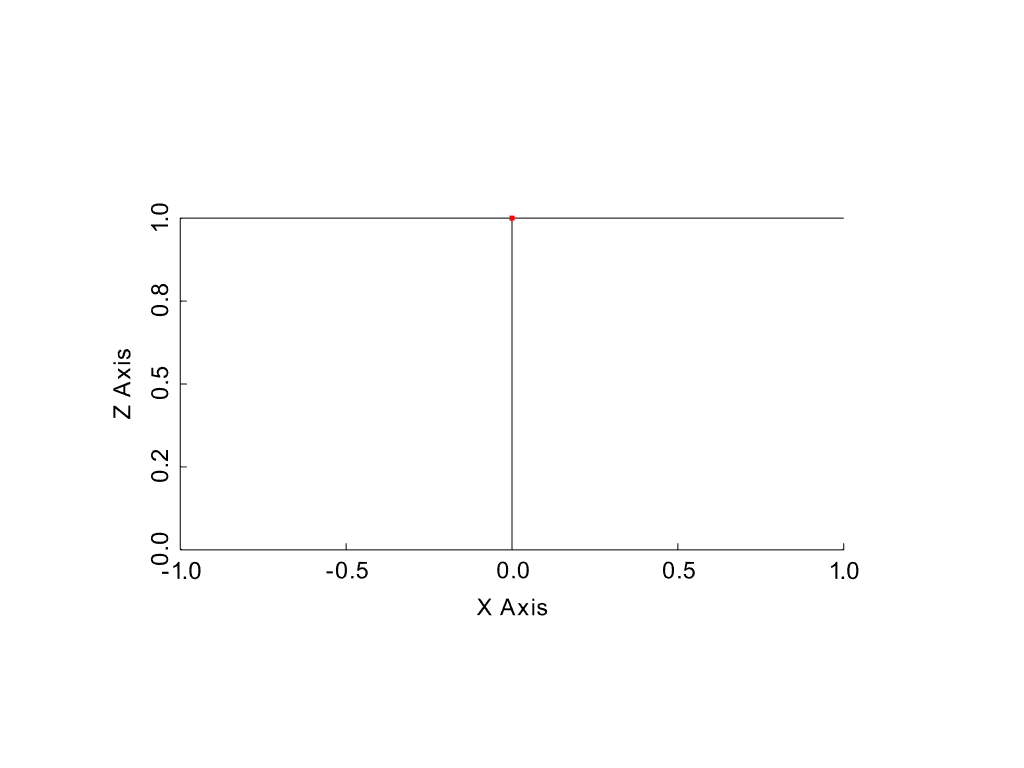

In [7]:
import pyvista as pv

plotter = pv.Plotter()

for edge_mesh in edge_meshes:
    topology, cell_types, geometry = dolfinx.plot.vtk_mesh(edge_mesh)
    grid1 = pv.UnstructuredGrid(topology, cell_types, geometry)
    plotter.add_mesh(grid1, show_edges=True, color="black")

topology_lm, cell_types_lm, geometry_lm = dolfinx.plot.vtk_mesh(lm_mesh)
grid_lm = pv.UnstructuredGrid(topology_lm, cell_types_lm, geometry_lm)
plotter.add_mesh(grid_lm, show_edges=True, color="red")

plotter.view_xz()
plotter.show_bounds()
plotter.screenshot("Y-mesh.png")
plotter.show()

In [8]:
lm_to_edge_maps = []
lm_indices = np.array([0], dtype=np.int32)

for i, vertex_map in enumerate(edge_vertex_maps):
  lm_graph_indices = lm_map.sub_topology_to_topology(lm_indices, inverse=False)
  lm_to_edge = edge_vertex_maps[i].sub_topology_to_topology(lm_graph_indices, inverse=True)
  cpp_map = dolfinx.cpp.mesh.EntityMap(
      edge_meshes[i].topology._cpp_object,
      lm_mesh.topology._cpp_object,
      0,
      lm_to_edge,
  )
  lm_to_edge_maps.append(dolfinx.mesh.EntityMap(cpp_map))

In [6]:
fs_edges = [dolfinx.fem.functionspace(edge_mesh, ("DG", 1)) for edge_mesh in edge_meshes]
fs_lm = dolfinx.fem.functionspace(lm_mesh, ("DG", 0))

function_spaces = ufl.MixedFunctionSpace(*[*fs_edges, fs_lm])

trial_funs = ufl.TrialFunctions(function_spaces)
u_1d = trial_funs[:-1]
u_lm = trial_funs[-1]

test_funs = ufl.TestFunctions(function_spaces)
w_1d = test_funs[:-1]
w_lm = test_funs[-1]

In [7]:
f_edges = [
    1,
    1,
    1,
]

In [ ]:
a = [
    [ufl.ZeroBaseForm((ui, vj)) for vj in test_funs] for ui in trial_funs
]
L = [
    ufl.ZeroBaseForm((ui,)) for ui in test_funs
]

sigma_omega = 20
sigma_e = 20
sigma_bifurc = 20

for i, (edge, facet_marker) in enumerate(zip(edge_meshes, edge_facet_markers)):
    dx_edge = ufl.Measure("dx", domain=edge)
    dS_edge = ufl.Measure("dS", domain=edge)
    ds_edge = ufl.Measure("ds", domain=edge, subdomain_data=facet_marker)

    dx_bifurc = ufl.Measure("dx", lm_mesh)

    # Use a constant scalar for h_e inside the 0D term to avoid compiling 1D variables on a 0D domain
    # We calculate the physical cell size (assuming uniform intervals in the submesh)
    coords = edge.geometry.x
    h_e_val = float(np.linalg.norm(coords[1] - coords[0]))

    h_e = ufl.CellDiameter(edge)
    h_e_avg = (h_e("+") + h_e("-"))/2
    n_e = ufl.FacetNormal(edge)

    # DG Form - Diagonal blocks
    a[i][i] = ufl.inner(ufl.grad(u_1d[i]), ufl.grad(w_1d[i])) * dx_edge
    a[i][i] -= ufl.inner(ufl.avg(ufl.grad(u_1d[i])), ufl.jump(w_1d[i], n_e)) * dS_edge
    a[i][i] -= ufl.inner(ufl.avg(ufl.grad(w_1d[i])), ufl.jump(u_1d[i], n_e)) * dS_edge
    a[i][i] += (sigma_e / h_e_avg) * ufl.inner(ufl.jump(u_1d[i], n_e), ufl.jump(w_1d[i], n_e)) * dS_edge

    # Bifurcation node coupling
    a[i][i] += ufl.inner(ufl.grad(u_1d[i]), ufl.outer(w_1d[i], n_e)) * ds_edge(bifurc_marker)
    a[i][i] += ufl.inner(ufl.grad(w_1d[i]), ufl.outer(u_1d[i], n_e)) * ds_edge(bifurc_marker)
    a[i][i] += (sigma_bifurc / h_e) * ufl.inner(u_1d[i], w_1d[i]) * ds_edge(bifurc_marker)

    a[-1][i] = ufl.inner(ufl.grad(u_1d[i]), ufl.outer(w_lm, n_e)) * ds_edge(bifurc_marker)
    a[i][-1] = ufl.inner(ufl.grad(w_1d[i]), ufl.outer(u_lm, n_e)) * ds_edge(bifurc_marker)

    a[-1][i] = (sigma_bifurc / h_e) * ufl.inner(u_1d[i], w_lm) * ds_edge(bifurc_marker)
    a[i][-1] = (sigma_bifurc / h_e) * ufl.inner(w_1d[i], u_lm) * ds_edge(bifurc_marker)

    # Use h_e_val (the scalar float) here instead of the UFL object h_e
    a[-1][-1] = (sigma_bifurc / h_e_val) * u_lm * w_lm * dx_bifurc

    # RHS Form
    L[i+1] = ufl.inner(w_1d[i], f_edges[i]) * dx_edge
    #L[i+1] -= ufl.inner(ufl.grad(self._w_e[i]), ufl.outer(self._u_ex_edges[i], n_e)) * ds_edge(self._boundary_marker)
    #L[i+1] += (self._sigma_edge / h_e) * ufl.inner(self._u_ex_edges[i], self._w_e[i]) * ds_edge(self._boundary_marker)

entity_maps = edge_entity_maps + [lm_map] + lm_to_edge_maps

for i, ai in enumerate(a):
    for j, aij in enumerate(ai):
          if isinstance(aij, ufl.ZeroBaseForm):
              a[i][j] = None


In [55]:
print(len(a[3][0].arguments()))

2


In [ ]:
a_form = a[3][0]



<class 'ufl.form.Form'>


In [45]:
A_blocks = []
for i, row in enumerate(a):
    A_row = []
    for j, form in enumerate(row):
        if form is not None:
            print(f"{i}, {j}")
            A_ij = create_matrix(form, entity_maps=entity_maps)
            A_row.append(A_ij)
            print("success")
        else:
            print(f"{i}, {j}")
            A_row.append(None)
            print("success")
    A_blocks.append(A_row)

A_mat = PETSc.Mat().createNest(A_blocks, comm=comm)
A_mat.assemble()

0, 0
success
0, 1
success
0, 2
success
0, 3
success
1, 0
success
1, 1
success
1, 2
success
1, 3
success
2, 0
success
2, 1
success
2, 2
success
2, 3
success
3, 0


ValueError: Found multiple domains, cannot return just one.